# Fundamental photon noise limit to radial velocity measurements for HARPS3.

Considering that $N_{e^-}$ is the total number of photoelectrons counted over the whole spectral range, the uncertainty of the velocity change is given by Bouchy et al. [[1]](https://doi.org/10.1051/0004-6361:20010730):

$$
V_{\mathrm{RMS}} = \frac{c}{Q\sqrt{N_{e^-}}}. \tag{1}
$$

With the quality factor Q and the total number of photoelectrons $N_{e^-}$, the fundamental noise limitation in velocity measurements can be calculated. The quality factor in Eq. (1) may be computed for any stellar spectrum. We will use stellar spectrum for stars that the Terra Hunting Experiment will target.

To compute the fundamental uncertainty on RV by Eq. (1), we must estimate the total number of photoelectrons collected over the spectral range of interest. The total number of photoelectrons counted over each slice of 100Å is given by: 

$$
N_{e^-} = \frac{F_{*}\cdot S_{tel} \cdot e_{tot} \cdot t_{exp}}{2.512^{mv}} \tag{2}
$$

where:
- $S_{tel}$ the telescope area in $\text{m}^{2}$,
- $e_{tot}$ the total efficiency including atmosphere, spectrograph and detector.
- $t_{exp}$ the exposure time in s.
- $mv$ the visual magnitude of the star.
- $F_{*}$ is the spectral flux calculated from target star in (photon $\text{m}^{2} \text{s}^{-1}$).

Our goal is to calculate the fundamental photon noise limit for observations taken with the [HARPS3 telescope](https://www.ing.iac.es/PR/inst.php?tel=int&inst=HARPS3), a high resolution (R~115,000) echelle spectrograph with a wavelength range from 380-690 $\text{nm}$.

For HARPS3, the primary mirror is 2.54 m in diameter with a central obscuration of 0.914 m diameter; the effective collecting area is therefore 4.41 $\text{m}^{2}$ ($S_{tel} = 4.41 \text{ m}^{2}$).

The exposure time for HARPS3 is $t_{exp}$ = 15 minutes and a cautious average total efficiency of $e_{tot}$ = 5% for the system. This differs if the polarimeter in the system is included, with the total efficiency being less than 5%, down to 1% across the spectral range.

HARPS3 operates under the [Terra Hunting Experiment](https://www.terrahunting.org/goals.html) (THE), which will primarily search for a “searchable star” as a G or K dwarf star. This type of star can provide enough data for a secure detection of a Doppler signal with a semi-amplitude K = 10 cm/s and signal between 60 to 400 days (Earth-like exoplanet). 

We will use a V = 7.5 G6V star as our standard star for simulations as in Hall et al. [[3]](https://doi.org/10.1093/mnras/sty1464).

In [21]:
tot_eff = 5 / 100 # total efficiency of the system.
t_exp = 15 * 60 # exposure time for HARPS3.
V_mag = 7.5 # apparent magnitude of the star.
S_area = 4.41 # telescope area
spectral_range = (3800, 6900) # HARPS3 spectral range in Å

## Synthetic stellar spectrum

To calculate the spectral flux $F_{*}$ of the target star, we need a synthetic stellar spectrum. For this we use the [Kurucz 1993 Atlas](https://www.stsci.edu/hst/instrumentation/reference-data-for-calibration-and-tools/astronomical-catalogs/kurucz-1993-models) via the [HLSP data product catalogue](https://www.stsci.edu/hst/instrumentation/reference-data-for-calibration-and-tools/astronomical-catalogs), which contains about 7600 stellar atmosphere models covering a wide range of metallicities, effective temperatures and surface gravities.

Our target star (G6V) has the following atmospheric parameters:

| Parameter | Symbol | Value |
|:--|:--:|--:|
| Effective temperature | $T_{\mathrm{eff}}$ | 5600 K |
| Metallicity | $[\mathrm{M/H}]$ | 0.0 |
| Surface gravity | $\log g$ | 4.5 |

In [2]:
temp_star = 5600 # effective temperature of the target star.
metallicity = 0.0 # metallicity of the target star.
log_g = 4.5 # log of surface gravity of the target star.

### Setting up libraries

In [46]:
from matplotlib import pyplot as plt
import numpy as np

from astropy import units as u
from astropy import constants as const


import os
os.environ["PYSYN_CDBS"] = os.path.expanduser("~/projects/trds")   # must come before the import, and edit to where you stored.

import stsynphot as stsyn
print(stsyn.conf.rootdir)
print(os.path.isfile(os.path.join(stsyn.conf.rootdir, "grid", "k93models", "catalog.fits")))

from stsynphot import catalog

idx, _ = catalog.get_catalog_index("k93models")  # list of [Teff, [M/H], log g, filename]
sp = stsyn.grid_to_spec("k93models", temp_star, metallicity, log_g) # extract stellar spectra from Teff, [M/H], log g

from synphot import units, SpectralElement

/Users/enisgerxhaljia/projects/trds
True


### Plot of stellar spectrum above earth's atmosphere within HARPS3 spectral range.

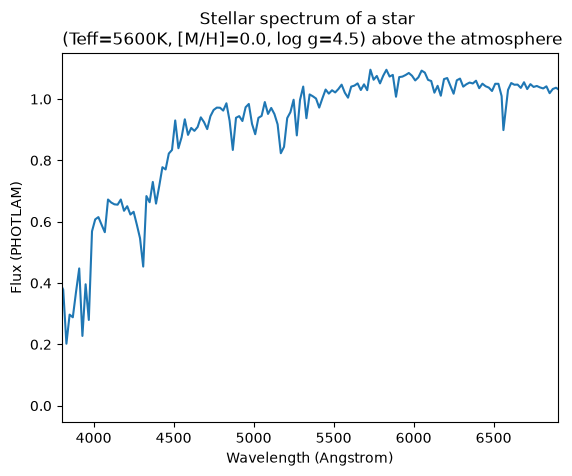

In [ ]:
idx, _ = catalog.get_catalog_index("k93models")  # list of [Teff, [M/H], log g, filename]
sp = stsyn.grid_to_spec("k93models", temp_star, metallicity, log_g) # extract stellar spectra from Teff, [M/H], log g with units photons s⁻¹ cm⁻² Å⁻¹

V_filter = SpectralElement.from_filter("johnson_v") # the V filter's transmission curve
sp_earth = sp.normalize(V_mag * units.VEGAMAG, band=V_filter, vegaspec=stsyn.Vega) # normalise to the apparent magnitude of the star in the V band


sp_earth.plot(left=spectral_range[0], right=spectral_range[1], flux_unit=units.PHOTLAM, title="Stellar spectrum of a star \n (Teff=5600K, [M/H]=0.0, log g=4.5) above the atmosphere")

(100000.0, 2000000.0)

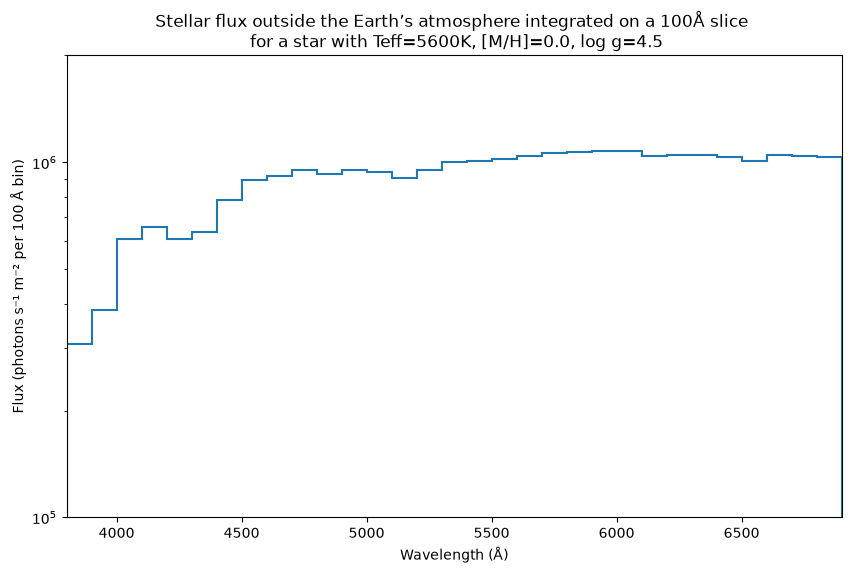

In [42]:
wave = sp_earth.waveset # the model's own wavelengths, in Å
flux = sp_earth(wave, flux_unit=units.PHOTLAM)  # photons s⁻¹ cm⁻² Å⁻¹

wave_A = wave.to_value(u.AA)
F_star = flux.value * 1e4  # photons s⁻¹ m⁻² Å⁻¹

edges = np.arange(spectral_range[0], spectral_range[1] + 100, 100) # 100 Å bin edges across HARPS3
dlam = np.gradient(wave_A)  # width of each model wavelength sample, in Å
flux_bins = np.histogram(wave_A, bins=edges, weights=F_star * dlam)[0]  # integrated flux in each bin (F dλ summed)
plot_edges = edges[:-1] + 50  # bin centers for plotting
plt.figure(figsize=(10, 6))
plt.stairs(flux_bins, edges, lw=1.5)  # flat across each bin at the bin value
plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux (photons s⁻¹ m⁻² per 100 Å bin)")
plt.yscale('log')  # base-10 log y-axis
plt.title("Stellar flux outside the Earth’s atmosphere integrated on a 100Å slice \n for a star with Teff=5600K, [M/H]=0.0, log g=4.5")
plt.xlim(spectral_range[0], spectral_range[1])
plt.ylim(1e5, 2e6)

### Plot of the quality factor versus fundamental $\delta V_{rv}$

In [ ]:

delta_rv = np.arange(0.01, 10, 0.01)  # radial velocity shifts in km/s
Q_factor = np.zeros_like(delta_rv)  # initialize Q factor array
photon_count = np.sum(flux_bins) * S_area * tot_eff * t_exp  # total photons collected in the exposure
Q_factor = const.c / ( np.sqrt(photon_count) * delta_rv )  # simplified Q factor calculation

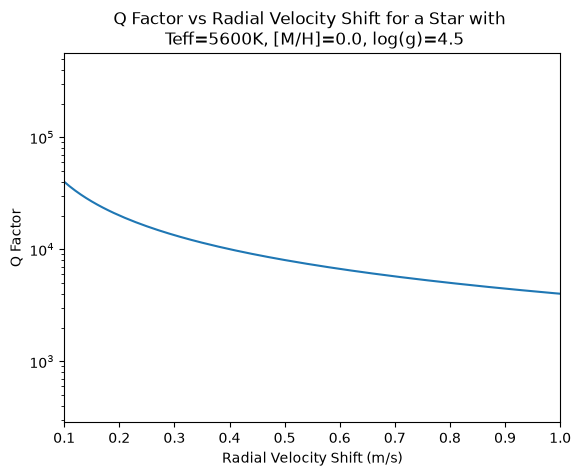

In [73]:
plt.plot(delta_rv, Q_factor)
plt.yscale('log')
plt.xlabel("Radial Velocity Shift (m/s)")
plt.ylabel("Q Factor")
plt.title("Q Factor vs Radial Velocity Shift for a Star with \n Teff=5600K, [M/H]=0.0, log(g)=4.5")
plt.xticks(np.arange(0.1, 1.1, 0.1))
plt.xlim([0.1, 1])
plt.show()

# References

[[1]](https://doi.org/10.1051/0004-6361:20010730) Bouchy, F., F. Pepe, and D. Queloz. “Fundamental Photon Noise Limit to Radial Velocity Measurements.” *Astronomy & Astrophysics* 374, no. 2 (2001): 733–39. https://doi.org/10.1051/0004-6361:20010730.

[[2]](https://doi.org/10.1117/12.2232111) Thompson, Samantha J., Didier Queloz, Isabelle Baraffe, et al. “HARPS3 for a Roboticized Isaac Newton Telescope.” In *Ground-Based and Airborne Instrumentation for Astronomy VI*, edited by Christopher J. Evans, Luc Simard, and Hideki Takami. Proceedings of SPIE 9908 (2016): 99086F. https://doi.org/10.1117/12.2232111.

[[3]](https://doi.org/10.1093/mnras/sty1464) Hall, Richard D., Samantha J. Thompson, Will Handley, and Didier Queloz. “On the Feasibility of Intense Radial Velocity Surveys for Earth-Twin Discoveries.” *Monthly Notices of the Royal Astronomical Society* 479, no. 3 (2018): 2968–87. https://doi.org/10.1093/mnras/sty1464.